## Generate cell population data for figure 3 for all six conditions

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "cellular_cycle")
sys.path.insert(0, "figures")

import fracprolif as fp

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files
LOAD_PRIOR = False # Load prior simulation files

SET_JPARAM = False
PSO_num = 2

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)

In [5]:
if SET_JPARAM:
    with open('fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
        frac_prolif_parameters_pso = pickle.load(f)
    new_param_pso_sort = frac_prolif_parameters_pso.sort_values([('cost', 'total cost likelihood')])
    new_params = new_param_pso_sort['model parameters']
    # Importing the parameters:
    for key in new_params.keys():
        try:
            if model.parameters[key].value != new_params[key].iloc[PSO_num]:
                print(f'Changing {key} from {model.parameters[key].value} to {new_param[key][0]}')
                model.parameters[key].value = new_params[key].iloc[PSO_num]
        except:
            print(f'{key} not found in model parameters')

In [6]:
# Setting initial concentrations
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [7]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


In [8]:
model.parameters['V_Di'].value

0.6

In [9]:
condition = "55 kPa erlotinib"
concs = [0, 0.001, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1., 2., 5.,]


In [10]:
DIPs_di = dict([(conc, []) for conc in concs])
population_dfs = dict([(conc, []) for conc in concs])
cell_counts_di = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

In [11]:
init = 10
run_time = 120
observed_cells_time = 120

In [12]:
def run_treatment(inhib_name, inhib_conc):
    model.parameters[inhib_name].value = inhib_conc
    (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model,
                                                                           ECM_conditions, condition,
                                                                           sampled_parameter_names, thr=[0.26, 0.14],
                                                                           return_plot=False, bypass=True)
    return cells, cell_count, population_df

In [37]:
fn_DIPs = Path('../Data/DIPrates_CDK4-6i_df.csv')
fn_pops = Path('../Data/cellfate_CDK4-6i_df.pkl')

In [38]:

n=0
for conc in concs:
    for i in range(5):
        cells, cell_count, population_df = run_treatment('CycDi_0', conc)
        cell_counts_di[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_di[conc].append(dip_rate)
        population_dfs[conc].append(population_df)
    n+=1

DIPs_di_df = pd.DataFrame(DIPs_di).T

55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotinib
55 kPa erlotin

### Save DIP rates by CDK4/6i conc and population dataframe

In [43]:
# fn defined above
if not Path(fn_DIPs).exists() or OVERWRITE:
    print(f'Saving to {fn_DIPs}')
    DIPs_di_df.to_csv(fn_DIPs)
else:
    print(f'File exists: {fn_DIPs}')

Saving to ..\Data\DIPrates_CDK4-6i_df.csv


In [44]:
if not Path(fn_pops).exists() or OVERWRITE:
    print(f'Saving to {fn_pops}')
    with open(fn_pops, 'wb') as f:
        pickle.dump(population_dfs, f)
else:
    print(f'File exists: {fn_pops}')

Saving to ..\Data\cellfate_CDK4-6i_df.pkl


### Save files of cell counts over time from each of 5 simulations per condition

In [20]:
cell_counts_dil = {}
for cond in cell_counts_di:
    tmp = [run.tolist() for run in cell_counts_di[cond]]
    cell_counts_dil.update({cond: tmp})

In [21]:
# a_rates_dil = {}
# for cond in a_rate_di:
#     tmp = [run for run in a_rate_di[cond]]
#     a_rates_dil.update({cond: tmp})

In [22]:
import json

fn = SAVE_DIR / 'cdk46i_0.4_cellcounts.json'

if not fn.exists() or OVERWRITE:
    print(f'Writing {fn}')
    with open(fn, 'w') as f: 
        json.dump(cell_counts_dil, f)
else:
    print(f'{fn} exists. Skipping.')

Writing /Users/darren/ECM_mod_output/cdk46i_0.4_cellcounts.json


In [23]:
# fig, ax = make_fig(cell_count, run_time, title=condition)
# add_plot(cell_count, run_time, fig, ax, title=condition)

### Simulation using 10 initial cells for a total of 200 cell IMTs (for G1 calculation)

In [24]:
model.parameters['CycDi_0'].value = 0.4


In [17]:
ECM_conditions.condition.unique()

array(['55 kPa DMSO', '4 kPa DMSO', '0.6 kPa DMSO', '55 kPa erlotinib',
       '4 kPa erlotinib', '0.6 kPa erlotinib'], dtype=object)

In [19]:
for condition in ECM_conditions.condition.unique():
    runIMTs(10, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, IMTs_count=200, inhib='none', SAVE_DIR=SAVE_DIR, verbose=True)

55 kPa DMSO
retieving cell state of 538 cells
runIMT round 0 has 532 IMT values
Saving C:\Users\olesk\ECM_mod_output\IMTs_55 kPa DMSO_none.csv, C:\Users\olesk\ECM_mod_output\G1s_55 kPa DMSO_none.csv, and C:\Users\olesk\ECM_mod_output\SMs_55 kPa DMSO_none.csv...
4 kPa DMSO
retieving cell state of 412 cells
runIMT round 0 has 396 IMT values
Saving C:\Users\olesk\ECM_mod_output\IMTs_4 kPa DMSO_none.csv, C:\Users\olesk\ECM_mod_output\G1s_4 kPa DMSO_none.csv, and C:\Users\olesk\ECM_mod_output\SMs_4 kPa DMSO_none.csv...
0.6 kPa DMSO
retieving cell state of 188 cells
runIMT round 0 has 172 IMT values
0.6 kPa DMSO
retieving cell state of 145 cells
runIMT round 1 has 303 IMT values
Saving C:\Users\olesk\ECM_mod_output\IMTs_0.6 kPa DMSO_none.csv, C:\Users\olesk\ECM_mod_output\G1s_0.6 kPa DMSO_none.csv, and C:\Users\olesk\ECM_mod_output\SMs_0.6 kPa DMSO_none.csv...
55 kPa erlotinib
retieving cell state of 180 cells
runIMT round 0 has 170 IMT values
55 kPa erlotinib
retieving cell state of 224 cel

### Plotting growth curves

In [28]:
cell_fates = population_dfs[0.4][1]
cell_fates


,Old ID,New ID,Lineage,Event,Start Time,Birth Time,End Time,Starting Cell,Lifetime
0,0,0,Initial cell,Mitosis,0.000000,Initial cell,0.401338,True,0.401338
1,0,28,0,End of experiment,0.401338,0.401338,120.000000,False,119.598662
2,1,1,Initial cell,Mitosis,0.000000,Initial cell,3.511706,True,3.511706
3,1,29,1,End of experiment,3.511706,3.511706,120.000000,False,116.488294
4,2,2,Initial cell,Mitosis,0.000000,Initial cell,3.913043,True,3.913043
5,2,30,2,Mitosis,3.913043,3.913043,104.548495,False,100.635452
6,2,31,30,End of experiment,104.548495,104.548495,120.000000,False,15.451505
7,3,3,Initial cell,Mitosis,0.000000,Initial cell,9.431438,True,9.431438
8,3,32,3,End of experiment,9.431438,9.431438,120.000000,False,110.568562
9,4,4,Initial cell,Mitosis,0.000000,Initial cell,114.983278,True,114.983278


dict_keys([0, 0.001, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0, 2.0, 5.0])

In [31]:
cell_count = cell_counts_di[0.4][0]

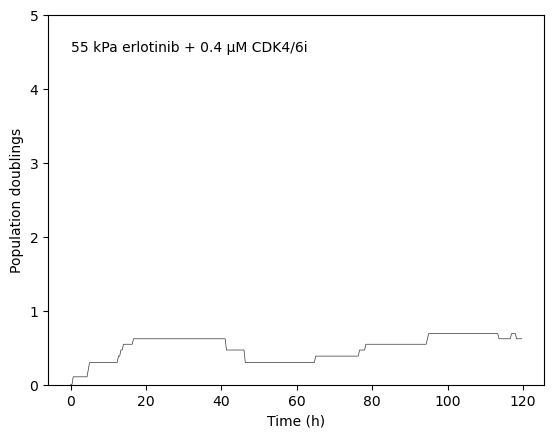

In [38]:
fig, ax = make_fig(cell_count, run_time, title=f'{condition} + 0.4 µM CDK4/6i')
add_plot(cell_counts_di[0.4][3], run_time, fig, ax)

### Trying to assemble single-cell data into a single DataFrame

In [52]:
# Initialize an empty list to store all dataframes with multi-index
df_list = []

# Iterate through the dictionary
for key in population_dfs.keys():
    for i, df in enumerate(population_dfs[key]):
        # Create a multi-index for each dataframe
        df = df.copy()
        df['CDK4/6i'] = key
        df['run'] = i
        df.set_index(['CDK4/6i', 'run'], append=True, inplace=True)
        
        # Append the modified dataframe to the list
        df_list.append(df)

# Concatenate all dataframes into a single dataframe
result_df = pd.concat(df_list)
result_df.head()


,,,Old ID,New ID,Lineage,Event,Start Time,Birth Time,End Time,Starting Cell,Lifetime
,CDK4/6i,run,,,,,,,,,
0,0.0,0,0,0,Initial cell,Mitosis,0.000000,Initial cell,0.000000,True,0.000000
1,0.0,0,0,200,0,Mitosis,0.000000,0,16.354515,False,16.354515
2,0.0,0,0,201,200,Apoptosis,16.354515,16.354515,32.207358,False,15.852843
3,0.0,0,1,1,Initial cell,Mitosis,0.000000,Initial cell,0.000000,True,0.000000
4,0.0,0,1,202,1,Mitosis,0.000000,0,14.648829,False,14.648829


In [55]:
result_df.to_csv(SAVE_DIR / 'cdk46i_0.4_population_df.csv')

In [56]:
cell_counts_di.keys()

dict_keys([0, 0.001, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0, 2.0, 5.0])

In [59]:
pd.DataFrame(cell_counts_di).to_csv(SAVE_DIR / 'cdk46i_cell_counts.csv')

array([[ 0.        , 14.        ],
       [ 0.2006689 , 15.        ],
       [ 1.00334448, 17.        ],
       [ 1.20401338, 18.        ],
       [ 7.02341137, 19.        ]])

In [60]:
df_list2 = []

# Iterate through the dictionary
for key in cell_counts_di.keys():
    for i, df in enumerate(cell_counts_di[key]):
        # Create a multi-index for each dataframe
        df = pd.DataFrame(df).copy()
        df['CDK4/6i'] = key
        df['run'] = i
        df.set_index(['CDK4/6i', 'run'], append=True, inplace=True)
        
        # Append the modified dataframe to the list
        df_list2.append(df)

# Concatenate all dataframes into a single dataframe
cell_counts_df = pd.concat(df_list2)
cell_counts_df.head()

,,,0,1
,CDK4/6i,run,,
0,0.0,0,0.000000,14.0
1,0.0,0,0.200669,15.0
2,0.0,0,1.003344,17.0
3,0.0,0,1.204013,18.0
4,0.0,0,7.023411,19.0


In [61]:
cell_counts_df.shape

(10960, 2)

In [62]:
cell_counts_df.to_csv(SAVE_DIR / 'cdk46i_cell_counts.csv')

### Generate cell populations +DMSO +Cdk4/6i

In [32]:
condition = "55 kPa DMSO"

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 1
model.parameters['CycDi_0'].value = 0.4

In [33]:
init = 10
run_time = 120
observed_cells_time = 120

In [34]:
df_list2 = []

for ii in range(3):
    (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, 
                                                                           model, ECM_conditions, condition, 
                                                                           sampled_parameter_names, thr=[0.26, 0.14], 
                                                                           return_plot=False, bypass=True)
    df = pd.DataFrame(cell_count)
    df['CDK4/6i'] = model.parameters['CycDi_0'].value
    df['run'] = ii
    df.set_index(['CDK4/6i', 'run'], append=True, inplace=True)

    # Append the modified dataframe to the list
    df_list2.append(df)

# Concatenate all dataframes into a single dataframe
cell_counts_df = pd.concat(df_list2)

0.6 kPa DMSO
0.6 kPa DMSO


KeyboardInterrupt: 

In [ ]:
cell_counts_df.to_csv(SAVE_DIR / 'cdk46i_dmso_cell_counts.csv')

### Checking model output

In [38]:
condition = "0.6 kPa erlotinib"

model.parameters['AKT'].value = 0.3
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4
model.parameters['CycDi_0'].value = 0

In [39]:
init = 10
run_time = 120
observed_cells_time = 120

In [40]:
(check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, 
                                                                           model, ECM_conditions, condition, 
                                                                           sampled_parameter_names, thr=[0.26, 0.14], 
                                                                           return_plot=False, bypass=True)

0.6 kPa erlotinib


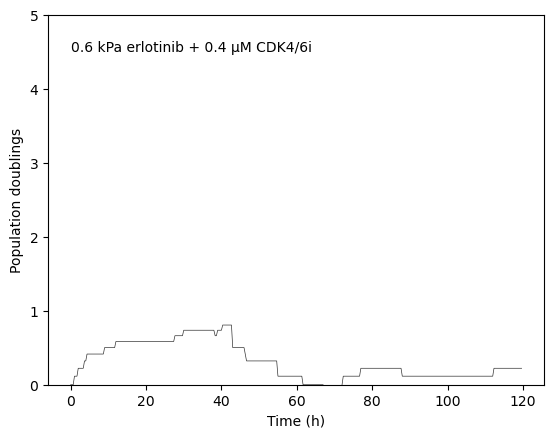

In [41]:
fig, ax = make_fig(cell_count, run_time, title=f'{condition} + 0.4 µM CDK4/6i')
add_plot(cell_count, run_time, fig, ax)

In [42]:
population_df

,Old ID,New ID,Lineage,Event,Start Time,Birth Time,End Time,Starting Cell,Lifetime
0,0,0,Initial cell,Mitosis,0.000000,Initial cell,11.839465,True,11.839465
1,0,29,0,Apoptosis,11.839465,11.839465,42.943144,False,31.103679
2,1,1,Initial cell,Mitosis,0.000000,Initial cell,8.729097,True,8.729097
3,1,30,1,Apoptosis,8.729097,8.729097,42.240803,False,33.511706
4,2,2,Initial cell,Mitosis,0.000000,Initial cell,27.391304,True,27.391304
5,2,31,2,Apoptosis,27.391304,27.391304,73.344482,False,45.953177
6,3,3,Initial cell,Mitosis,0.000000,Initial cell,14.849498,True,14.849498
7,3,32,3,Apoptosis,14.849498,14.849498,54.782609,False,39.933110
8,4,4,Initial cell,Mitosis,0.000000,Initial cell,0.000000,True,0.000000
9,4,33,4,Apoptosis,0.000000,0,67.224080,False,67.224080


In [43]:
cells['molecules'][0]['obsBCL2'][0]

149.0